<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/7_4_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile dft_1d.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <fstream>
#include <random>

const double PI = std::acos(-1.0);

// Sinüs Sinyali Üretici (Önceki Görevlerden)
void generateSineWave(std::vector<double>& vec, double amplitude, double frequency, double phase) {
    size_t n = vec.size();
    for (size_t i = 0; i < n; ++i) {
        vec[i] = amplitude * std::sin(2.0 * PI * frequency * (static_cast<double>(i) / n) + phase);
    }
}

// Gürültü Ekleyici (önceden biliyoruz)
void addNoise(std::vector<double>& vec, double noise_ratio) {
    double max_amp = 0.0;
    for (double v : vec) if (std::abs(v) > max_amp) max_amp = std::abs(v);

    double bound = max_amp * noise_ratio;
    std::random_device rd;
    std::mt19937 gen(rd());
    std::uniform_real_distribution<> dis(-bound, bound);

    for (double& v : vec) v += dis(gen);
}

// =========================================================================
// 4. GÖREV: 1D Ayrık Fourier Dönüşümü (DFT) Hesaplayan Fonksiyon
// =========================================================================
// Girdi  : Zaman/Uzam uzayındaki (Time Domain) N boyutlu sinyal vektörü
// Çıktı : Frekans uzayındaki (Frequency Domain) N boyutlu harmonik (Genlik) vektörü
std::vector<double> computeDFT(const std::vector<double>& input_signal) {
    size_t N = input_signal.size();
    std::vector<double> magnitude_spectrum(N, 0.0);

    // K frekansı için tüm uzamsal x'leri dolaşıp karmaşık sayılar (Euler) formülünü uyguluyoruz
    for (size_t k = 0; k < N; ++k) {
        double real_sum = 0.0;
        double imag_sum = 0.0;

        for (size_t x = 0; x < N; ++x) {
            double angle = 2.0 * PI * k * x / N;
            // Euler Formülü: e^(-j * angle) = cos(angle) - j*sin(angle)
            real_sum += input_signal[x] * std::cos(angle);
            imag_sum -= input_signal[x] * std::sin(angle);
        }

        // Karmaşık sayının büyüklüğünü (Genlik / Magnitude) bulma
        // Formül: sqrt(Real^2 + Imag^2)
        // Normalize etmek için N'ye bölüyoruz (Frekans spektrumunda tepe noktası net çıksın diye)
        magnitude_spectrum[k] = std::sqrt(real_sum * real_sum + imag_sum * imag_sum) / N;
    }

    return magnitude_spectrum;
}

int main() {
    size_t N = 256; // 2^8

    // 1. Gürültüsüz (Temiz) Sinyali Üret (Örn: Frekans = 4, Genlik = 50)
    std::vector<double> clean_signal(N);
    generateSineWave(clean_signal, 50.0, 4.0, 0.0);

    // 2. Gürültülü Sinyali Üret (%40 oranında beyaz gürültü ekleyelim)
    std::vector<double> noisy_signal = clean_signal;
    addNoise(noisy_signal, 0.40);

    // 3. Her iki sinyale DFT uygulayarak Frekans Uzayına (Harmonik Vektörlerine) geçir
    std::vector<double> clean_harmonic = computeDFT(clean_signal);
    std::vector<double> noisy_harmonic = computeDFT(noisy_signal);

    // 4. Sonuçları Görselleştirme (Python ile çizmek) için CSV'ye kaydet
    std::ofstream outFile("dft_sonuclari.csv");
    outFile << "Index,Clean_Signal,Noisy_Signal,Clean_Harmonic,Noisy_Harmonic\n";
    for (size_t i = 0; i < N; ++i) {
        outFile << i << ","
                << clean_signal[i] << ","
                << noisy_signal[i] << ","
                << clean_harmonic[i] << ","
                << noisy_harmonic[i] << "\n";
    }
    outFile.close();

    std::cout << "DFT islemi tamamlandi. Sonuclar 'dft_sonuclari.csv' dosyasina kaydedildi." << std::endl;
    return 0;
}

Writing dft_1d.cpp


In [2]:
!g++ dft_1d.cpp -o dft_1d
!./dft_1d

DFT islemi tamamlandi. Sonuclar 'dft_sonuclari.csv' dosyasina kaydedildi.


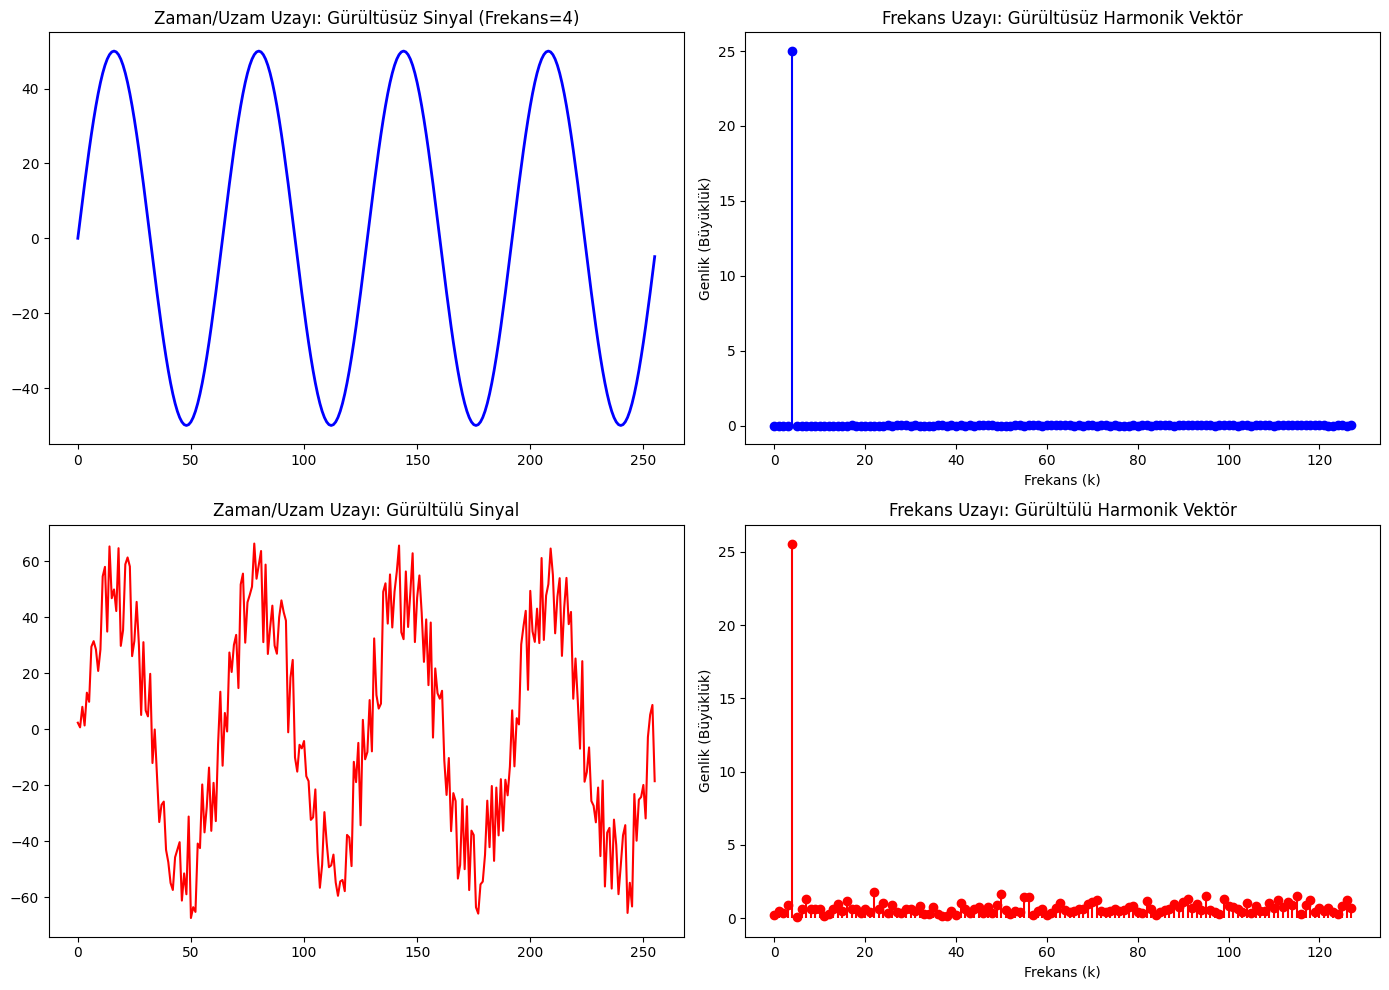

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('dft_sonuclari.csv')
N = len(df)
half_N = N // 2  # DFT simetrik olduğu için genelde sadece ilk yarısı (Nyquist frekansına kadar) çizilir.

plt.figure(figsize=(14, 10))

# 1. Uzamsal Gürültüsüz Sinyal
plt.subplot(2, 2, 1)
plt.plot(df['Index'], df['Clean_Signal'], color='blue', linewidth=2)
plt.title('Zaman/Uzam Uzayı: Gürültüsüz Sinyal (Frekans=4)')

# 2. Gürültüsüz Sinyalin Harmonik (Frekans) Vektörü
plt.subplot(2, 2, 2)
# Sadece ilk yarıyı çizdiriyoruz (0'dan 128'e kadar)
plt.stem(df['Index'][:half_N], df['Clean_Harmonic'][:half_N], linefmt='blue', basefmt=" ")
plt.title('Frekans Uzayı: Gürültüsüz Harmonik Vektör')
plt.xlabel('Frekans (k)')
plt.ylabel('Genlik (Büyüklük)')

# 3. Uzamsal Gürültülü Sinyal
plt.subplot(2, 2, 3)
plt.plot(df['Index'], df['Noisy_Signal'], color='red', linewidth=1.5)
plt.title('Zaman/Uzam Uzayı: Gürültülü Sinyal')

# 4. Gürültülü Sinyalin Harmonik (Frekans) Vektörü
plt.subplot(2, 2, 4)
plt.stem(df['Index'][:half_N], df['Noisy_Harmonic'][:half_N], linefmt='red', basefmt=" ")
plt.title('Frekans Uzayı: Gürültülü Harmonik Vektör')
plt.xlabel('Frekans (k)')
plt.ylabel('Genlik (Büyüklük)')

plt.tight_layout()
plt.show()